# R2 · Pretrained Word2Vec

Mean in-vocabulary word vectors per article → mean articles per window → concat with market and availability → MLP `(64, 32)`. No query, cross-attention, gate, or Word2Vec training. UP = USD/IDR rises (IDR depreciates).

Use the [shared split](../../SPLIT_PROTOCOL.md) and [ablation protocol](../../rules/ablation_protocol.md). Dependencies: NumPy, pandas, Matplotlib, scikit-learn, requests. Run outputs stay in this notebook; pretrained/subset caches use the OS temporary directory.

In [1]:
from pathlib import Path
import copy
import gzip
import io
import tempfile
import requests
import hashlib
import json
import platform
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from sklearn.utils import check_random_state
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "deira-work/SPLIT_PROTOCOL.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
BASE = ROOT / "deira-work/preprocessing/outputs/date_delay_sensitivity__audit_only"
MODEL_ID = "R2"
TEXT_WIDTH = 768
WORD_DIM = 300
SOURCE_VOCAB_SIZE = 3000000
PRETRAINED_PRIMARY_URL = "https://github.com/piskvorky/gensim-data/releases/download/word2vec-google-news-300/word2vec-google-news-300.gz"
PRETRAINED_URL = "https://huggingface.co/akashjd113/morale-ai-models/resolve/da6cb8fda49e823483cbd749ee40db73f7f30fa8/GoogleNews-vectors-negative300.bin.gz"
PRETRAINED_SHA256 = "cdd97c3b73abcd8e1437ad3837b8faf98fc21258f61f031721fe3e2096ed89d9"
PRETRAINED_MD5 = "a5e5354d40acb95f9ec66d5977d140ef"
PRETRAINED_BYTES = 1743563840
PRETRAINED_RELEASE = "2017-11-09T08:50:18Z"
CACHE_ROOT = Path(tempfile.gettempdir()) / "deira-r2-verified-model-20261110"
PRETRAINED_PATH = CACHE_ROOT / "word2vec-google-news-300.gz"
TEXT_FEATURES = [f"word2vec_{i:03d}" if i < WORD_DIM else f"zero_text_{i:03d}" for i in range(TEXT_WIDTH)]
AVAIL_FEATURES = ["log1p_n_berita", "has_news"]
SEEDS = [42, 123, 2026]
MAX_EPOCHS = 200
PATIENCE = 25
MLP_CONFIG = dict(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                  alpha=1e-3, batch_size=32, learning_rate_init=1e-3,
                  max_iter=1, shuffle=True, early_stopping=False)
RUN_FINAL_TEST = False  # Enable only after the experiment configurations are frozen.
BOOTSTRAP_REPEATS = 1000
BLOCK_LENGTH = 10       # Evaluated fixing observations; circular moving blocks.
BOOTSTRAP_SEED = 20261110
LABELS = ["DOWN", "UP"]
METRICS = ["mcc", "macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "log_loss", "ece_10"]
COLORS = ["#2563eb", "#ea580c", "#059669"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"{MODEL_ID} | seeds: {SEEDS} | final test enabled: {RUN_FINAL_TEST}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")

R2 | seeds: [42, 123, 2026] | final test enabled: False
Python 3.12.3 | pandas 3.0.5 | NumPy 2.5.3 | Matplotlib 3.11.2
scikit-learn 1.9.1


## Shared data

Reuse R1's exact dates, labels, retained articles, and windows. Read the prepared case-preserving Word2Vec tokens from the same headline/lead spans. Scalers fit only on train. Pretrained lookup is frozen; subset extraction is a memory cache, not vocabulary fitting on project text. Current news timing remains date-delay sensitivity.

In [2]:
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
pipeline = json.loads((BASE / "pipeline_manifest.json").read_text())
for name, expected in pipeline["input_sha256"].items():
    assert sha256(ROOT / name) == expected, f"Source snapshot changed: {name}"
assert pipeline["config"]["alignment_mode"] == "date_delay_sensitivity"
assert pipeline["config"]["geopolitical_policy"] == "audit_only"

contract = json.loads((BASE / "feature_contract.json").read_text())
MARKET_FEATURES = contract["market_features"]
FEATURES = MARKET_FEATURES.copy()
assert not set(FEATURES) & set(contract["target_and_diagnostic_columns_never_predictors"])
assert not set(FEATURES) & {"n_berita", "has_news", "y", "target_date", "next_jisdor"}
assert len(FEATURES) == len(set(FEATURES))
folds = pd.read_csv(BASE / "fold_manifest.csv", parse_dates=["Date", "target_date"])
final = pd.read_csv(BASE / "final_fit_manifest.csv", parse_dates=["Date", "target_date"])
daily = pd.read_csv(BASE / "daily_market.csv", parse_dates=["Date", "target_date"])
partitions = pd.read_csv(BASE / "calendar_partitions.csv", parse_dates=["Date", "target_date"])
assert not daily.Date.duplicated().any()
assert not folds.duplicated(["fold", "role", "Date"]).any()
assert not final.Date.duplicated().any()

def take_rows(rows):
    fields = ["Date", "target_date", "y", "eligible_binary", "n_berita", "has_news",
              "target_weekday", "realized_target_gap_days", *MARKET_FEATURES]
    joined = rows.merge(daily[fields], on="Date", how="left", validate="one_to_one", suffixes=("", "_daily"))
    assert len(joined) == len(rows) and joined.eligible_binary.all()
    assert joined.y.notna().all() and joined.y.isin([0, 1]).all()
    assert joined.target_date.eq(joined.target_date_daily).all()
    assert joined.y.eq(joined.y_daily).all()
    assert joined.n_berita.eq(joined.n_berita_daily).all()
    if "has_news_daily" in joined:
        assert joined.has_news.eq(joined.has_news_daily).all()
    assert np.isfinite(joined[MARKET_FEATURES].to_numpy(dtype=float)).all()
    return joined.drop(columns=[c for c in joined if c.endswith("_daily")]).sort_values("Date").reset_index(drop=True)

split_summary = []
seen_validation_dates = set()
for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    assert train.target_date.max() < val.Date.min()
    assert not set(train.Date) & set(val.Date)
    assert not seen_validation_dates & set(val.Date)
    seen_validation_dates.update(val.Date)
    for role, frame in [("train", train), ("validation", val)]:
        split_summary.append({"run": f"fold_{fold_id}", "role": role, "n": len(frame),
                              "first": frame.Date.min().date(), "last": frame.Date.max().date(),
                              "down": int(frame.y.eq(0).sum()), "up": int(frame.y.eq(1).sum()),
                              "news_days": int(frame.has_news.sum())})
final_train = take_rows(final.loc[final.role.eq("train")])
test_dates = final.loc[final.role.eq("test"), "Date"]
assert final_train.target_date.max() < test_dates.min()
assert not set(final_train.Date) & set(test_dates)
display(pd.DataFrame(split_summary))
print(f"Locked test: {test_dates.min().date()} to {test_dates.max().date()} | {len(test_dates)} eligible decisions")
print("Predictors:", ", ".join(FEATURES))
take_market_rows = take_rows

,run,role,n,first,last,down,up,news_days
0,fold_1,train,453,2021-09-29,2023-08-15,193,260,65
1,fold_1,validation,158,2023-08-21,2024-04-19,64,94,21
2,fold_2,train,612,2021-09-29,2024-04-19,257,355,86
3,fold_2,validation,159,2024-04-23,2024-12-12,78,81,32
4,fold_3,train,772,2021-09-29,2024-12-12,335,437,118
5,fold_3,validation,158,2024-12-16,2025-08-26,79,79,22


Locked test: 2025-08-29 to 2026-08-31 | 235 eligible decisions
Predictors: log_return_t, return_lag1, return_lag2, return_lag3, return_lag5, volatility_5, volatility_20, ma_ratio_5, ma_ratio_20, momentum_5, momentum_10, rsi_14, input_gap_days, decision_weekday


## Frozen pretrained vectors

Use [Google News Word2Vec](https://github.com/piskvorky/gensim-data/releases/tag/word2vec-google-news-300): 300-dimensional vectors for 3 million word/phrase entries. Its published 2017 asset predates this study; the exact corpus cutoff is not specified in the [catalog](https://raw.githubusercontent.com/piskvorky/gensim-data/master/list.json). Verify the published checksum before reading vectors.

Lookup is exact and case-sensitive, with no lowercase fallback, phrase joining, or word-vector normalization. Average known token occurrences per article; all-OOV articles become zero vectors and retain their news count. Window means include these zero articles. Pad 300 coordinates to the common 768-wide text input. Report OOV and effective parameter counts. First download is about 1.74 GB; only matching token vectors are retained in memory.

The pinned download mirror must match the original catalog MD5 and its recorded SHA-256.


In [3]:
def pretrained_file_hashes(path):
    md5, sha = hashlib.md5(usedforsecurity=False), hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            md5.update(chunk)
            sha.update(chunk)
    return md5.hexdigest(), sha.hexdigest()

def ensure_pretrained_file(path, url, expected_bytes, expected_md5):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.is_file():
        partial = path.with_suffix(path.suffix + '.part')
        offset = partial.stat().st_size if partial.is_file() else 0
        if offset > expected_bytes:
            raise ValueError('Partial pretrained asset exceeds its published size.')
        headers = {'Range': f'bytes={offset}-'} if offset else {}
        with requests.get(url, params={'download': '1', 'cache_time': str(time.time_ns())},
                          headers=headers, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            resume = bool(offset and response.status_code == 206)
            if resume:
                assert response.headers.get('Content-Range', '').startswith(f'bytes {offset}-')
            written = offset if resume else 0
            next_report = written + 128 * 1024 * 1024
            with partial.open('ab' if resume else 'wb') as handle:
                for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                    if not chunk:
                        continue
                    handle.write(chunk)
                    written += len(chunk)
                    if written >= next_report:
                        print(f'Downloaded {written / 1e6:.0f}/{expected_bytes / 1e6:.0f} MB', flush=True)
                        next_report += 128 * 1024 * 1024
        assert partial.stat().st_size == expected_bytes, 'Downloaded pretrained asset has an unexpected size.'
        md5, sha = pretrained_file_hashes(partial)
        assert md5 == expected_md5, 'Published pretrained checksum mismatch.'
        partial.replace(path)
    else:
        assert path.stat().st_size == expected_bytes
        md5, sha = pretrained_file_hashes(path)
        assert md5 == expected_md5, 'Cached pretrained asset failed its published checksum.'
    return {'published_md5': expected_md5, 'verified_md5': md5, 'source_sha256': sha,
            'source_bytes': expected_bytes, 'source_url': url}

article_path, window_path = BASE / "aligned_articles.jsonl", BASE / "news_windows.jsonl"
articles = pd.read_json(article_path, lines=True)
windows = pd.read_json(window_path, lines=True)
windows["Date"] = pd.to_datetime(windows.Date)
articles["anchor_date"] = pd.to_datetime(articles.anchor_date)
assert pipeline["config"]["word2vec_lowercase"] is False
assert articles.article_id.is_unique and windows.Date.is_unique
assert np.array_equal(windows.Date.to_numpy(), daily.Date.to_numpy())
assert np.array_equal(windows.n_berita.to_numpy(), daily.n_berita.to_numpy())
assert not articles.known_temporal_contamination.any()
assert articles.tokens_word2vec.map(lambda x: isinstance(x, list) and len(x) > 0).all()
article_index = articles.set_index("article_id")
window_index = windows.set_index("Date")
for row in windows.itertuples():
    assert len(row.article_ids) == row.n_berita
    for article_id in row.article_ids:
        assert article_id in article_index.index and row.Date == article_index.at[article_id, "anchor_date"]
FEATURES = [*MARKET_FEATURES, *TEXT_FEATURES, *AVAIL_FEATURES]
assert len(FEATURES) == len(set(FEATURES)) == 784

def array_sha256(value):
    return hashlib.sha256(np.ascontiguousarray(value).tobytes()).hexdigest()

def article_ids_for(dates):
    return sorted({article_id for date in dates for article_id in window_index.at[date, "article_ids"]})

def read_matching_binary_vectors(stream, wanted_tokens, expected_dim, expected_records=None):
    header = stream.readline().split()
    if len(header) != 2:
        raise ValueError("Expected a binary word2vec header: vocabulary_size dimension.")
    count, dimension = map(int, header)
    assert dimension == expected_dim and (expected_records is None or count == expected_records)
    wanted = {token.encode("utf-8"): token for token in wanted_tokens}
    found = {}
    for index in range(count):
        token = bytearray()
        while True:
            char = stream.read(1)
            if not char:
                raise EOFError("Truncated pretrained token record.")
            if char == b" ":
                break
            if char not in (b"\n", b"\r"):
                token.extend(char)
            if len(token) > 4096:
                raise ValueError("Unexpected pretrained token length or file format.")
        raw_vector = stream.read(4 * dimension)
        if len(raw_vector) != 4 * dimension:
            raise EOFError("Truncated pretrained vector.")
        key = wanted.get(bytes(token))
        if key is not None and key not in found:
            vector = np.frombuffer(raw_vector, dtype="<f4").copy()
            assert np.isfinite(vector).all()
            found[key] = vector
        if expected_records is not None and (index + 1) % 500000 == 0:
            print(f"Scanned {index + 1:,}/{count:,} pretrained records; matched {len(found):,} tokens")
    assert not stream.read(1024).strip() and stream.read(1) == b"", "Unexpected pretrained trailing records."
    return found, count

probe = io.BytesIO(b"3 2\nUS " + np.array([1., 2.], dtype="<f4").tobytes()
                   + b"\nus " + np.array([-1., 3.], dtype="<f4").tobytes()
                   + b"\nnot " + np.array([.5, -.5], dtype="<f4").tobytes() + b"\n")
probe_vectors, _ = read_matching_binary_vectors(probe, {"US", "not", "absent"}, 2)
assert set(probe_vectors) == {"US", "not"} and np.array_equal(probe_vectors["US"], [1., 2.])
del probe, probe_vectors

needed_dates = set(folds.Date)
if RUN_FINAL_TEST:
    needed_dates.update(final.Date)
needed_ids = article_ids_for(sorted(needed_dates))
needed_tokens = sorted({token for article_id in needed_ids for token in article_index.at[article_id, "tokens_word2vec"]})
subset_spec = {"source_md5": PRETRAINED_MD5, "dimension": WORD_DIM, "parser": "binary-float32-le-first-entry-v1",
               "case_sensitive": True, "lowercase_fallback": False,
               "needed_tokens_sha256": hashlib.sha256(json.dumps(needed_tokens, ensure_ascii=False).encode()).hexdigest()}
subset_key = hashlib.sha256(json.dumps(subset_spec, sort_keys=True).encode()).hexdigest()
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
subset_cache = CACHE_ROOT / f"subset_{subset_key}.npz"
started = time.perf_counter()
cache_hit = subset_cache.is_file()
if cache_hit:
    with np.load(subset_cache, allow_pickle=False) as cached:
        assert json.loads(str(cached["spec"])) == subset_spec
        vector_tokens, vector_matrix = cached["tokens"].tolist(), cached["vectors"].copy()
        pretrained_info = json.loads(str(cached["info"]))
    assert array_sha256(vector_matrix) == pretrained_info["subset_vectors_sha256"]
else:
    pretrained_info = ensure_pretrained_file(PRETRAINED_PATH, PRETRAINED_URL, PRETRAINED_BYTES, PRETRAINED_MD5)
    with gzip.open(PRETRAINED_PATH, "rb") as compressed:
        with io.BufferedReader(compressed, buffer_size=4 * 1024 * 1024) as stream:
            found, count = read_matching_binary_vectors(stream, needed_tokens, WORD_DIM, SOURCE_VOCAB_SIZE)
    if not found:
        raise ValueError("No project tokens matched the pretrained model; inspect tokenization and source.")
    vector_tokens = sorted(found)
    vector_matrix = np.stack([found[token] for token in vector_tokens]).astype(np.float32)
    del found
    pretrained_info.update({"source_vocab_size": count, "subset_vectors_sha256": array_sha256(vector_matrix),
                            "original_subset_extraction_seconds": time.perf_counter() - started})
    temporary = subset_cache.with_name(subset_cache.stem + ".partial.npz")
    np.savez_compressed(temporary, tokens=np.asarray(vector_tokens), vectors=vector_matrix,
                        spec=json.dumps(subset_spec), info=json.dumps(pretrained_info))
    temporary.replace(subset_cache)
assert pretrained_info["verified_md5"] == PRETRAINED_MD5
assert pretrained_info["source_sha256"] == PRETRAINED_SHA256
pretrained_info["primary_catalog_url"] = PRETRAINED_PRIMARY_URL
assert vector_matrix.shape == (len(vector_tokens), WORD_DIM) and np.isfinite(vector_matrix).all()
assert set(vector_tokens).issubset(needed_tokens)
vector_matrix.flags.writeable = False
word_vectors = dict(zip(vector_tokens, vector_matrix))

def mean_known_tokens(tokens):
    known = [word_vectors[token] for token in tokens if token in word_vectors]
    vector = np.mean(known, axis=0, dtype=np.float64) if known else np.zeros(WORD_DIM)
    return vector, len(known)

assert not mean_known_tokens(["___guaranteed_oov_token___"])[0].any()
article_vectors, article_coverage = {}, {}
for article_id in needed_ids:
    tokens = article_index.at[article_id, "tokens_word2vec"]
    vector, known = mean_known_tokens(tokens)
    article_vectors[article_id] = vector
    article_coverage[article_id] = {"tokens": len(tokens), "known_tokens": known}
pretrained_report = {**pretrained_info, **subset_spec, "model": "word2vec-google-news-300",
                     "asset_release_published_at": PRETRAINED_RELEASE, "exact_corpus_cutoff_documented": False,
                     "cache_hit": cache_hit, "current_subset_load_seconds": time.perf_counter() - started,
                     "required_unique_tokens": len(needed_tokens), "matched_unique_tokens": len(vector_tokens),
                     "full_pretrained_table_values": SOURCE_VOCAB_SIZE * WORD_DIM,
                     "loaded_frozen_vector_values": int(vector_matrix.size), "articles_encoded": len(needed_ids),
                     "normalization": "none", "automatic_phrase_joining": False}
print(f"Pretrained vectors: {len(vector_tokens):,}/{len(needed_tokens):,} needed token types matched; cache hit: {cache_hit}")
print(f"Article vectors: {len(article_vectors)} | native width: {WORD_DIM} | padded width: {TEXT_WIDTH}")

class FrozenWord2VecRepresentation:
    def __init__(self, training):
        self.training_dates = training.Date.tolist()
        self.training_ids = article_ids_for(self.training_dates)
        self.dimension = WORD_DIM
        self.coverage = {}
        self.vectors_sha = pretrained_info["subset_vectors_sha256"]

    def transform(self, frame, role):
        ids = article_ids_for(frame.Date)
        assert set(ids).issubset(article_vectors)
        if role in {"validation", "test"}:
            assert not set(ids) & set(self.training_ids)
        vectors = np.zeros((len(frame), TEXT_WIDTH), dtype=float)
        for index, row in enumerate(frame.itertuples()):
            news_ids = window_index.at[row.Date, "article_ids"]
            assert len(news_ids) == row.n_berita
            if news_ids:
                vectors[index, :WORD_DIM] = np.mean([article_vectors[article_id] for article_id in news_ids], axis=0)
        assert not vectors[frame.has_news.eq(0).to_numpy()].any()
        assert not vectors[:, WORD_DIM:].any() and np.isfinite(vectors).all()
        tokens = sum(article_coverage[article_id]["tokens"] for article_id in ids)
        known = sum(article_coverage[article_id]["known_tokens"] for article_id in ids)
        all_oov = sum(article_coverage[article_id]["known_tokens"] == 0 for article_id in ids)
        self.coverage[role] = {"articles": len(ids), "tokens": tokens, "known_tokens": known,
                               "oov_tokens": tokens - known, "token_coverage": known / tokens if tokens else None,
                               "oov_rate": 1 - known / tokens if tokens else None,
                               "all_oov_articles": all_oov, "article_ids": ids}
        result = pd.concat([frame.reset_index(drop=True), pd.DataFrame(vectors, columns=TEXT_FEATURES)], axis=1)
        result["log1p_n_berita"] = np.log1p(result.n_berita)
        return result

    def provenance(self, run):
        return {"run": run, "training_dates": [date.isoformat() for date in self.training_dates],
                "training_article_ids": self.training_ids, "native_dimension": WORD_DIM,
                "padded_text_width": TEXT_WIDTH, "subset_vectors_sha256": self.vectors_sha,
                "learned_text_numeric_parameters": 0, "training_on_project_text": False,
                "coverage": self.coverage}

Scanned 500,000/3,000,000 pretrained records; matched 8,116 tokens


Scanned 1,000,000/3,000,000 pretrained records; matched 8,190 tokens


Scanned 1,500,000/3,000,000 pretrained records; matched 8,229 tokens


Scanned 2,000,000/3,000,000 pretrained records; matched 8,249 tokens


Scanned 2,500,000/3,000,000 pretrained records; matched 8,258 tokens


Scanned 3,000,000/3,000,000 pretrained records; matched 8,262 tokens


Pretrained vectors: 8,262/9,335 needed token types matched; cache hit: False
Article vectors: 308 | native width: 300 | padded width: 768


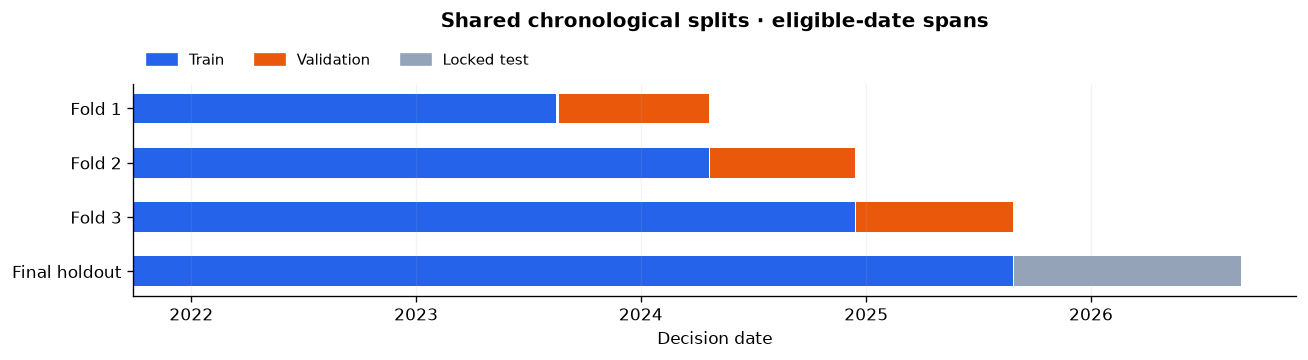

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.1))
for row, fold_id in enumerate(sorted(folds.fold.unique())):
    for role, color in [("train", COLORS[0]), ("validation", COLORS[1])]:
        dates = folds.loc[folds.fold.eq(fold_id) & folds.role.eq(role), "Date"]
        left = mdates.date2num(dates.min())
        width = mdates.date2num(dates.max()) - left + 1
        ax.barh(row, width, left=left, height=.55, color=color)
for role, color in [("train", COLORS[0]), ("test", "#94a3b8")]:
    dates = final.loc[final.role.eq(role), "Date"]
    ax.barh(3, mdates.date2num(dates.max()) - mdates.date2num(dates.min()) + 1,
            left=mdates.date2num(dates.min()), height=.55, color=color)
ax.set_yticks(range(4), ["Fold 1", "Fold 2", "Fold 3", "Final holdout"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Shared chronological splits · eligible-date spans", pad=34)
ax.set_xlabel("Decision date")
ax.legend(handles=[Patch(color=COLORS[0], label="Train"), Patch(color=COLORS[1], label="Validation"),
                   Patch(color="#94a3b8", label="Locked test")], loc="lower left", bbox_to_anchor=(0, 1.01),
          ncol=3, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()

## Training and metrics

Same MLP widths `(64, 32)`, seeds `[42, 123, 2026]`, Adam settings, 200-epoch limit, patience 25, threshold 0.5, and checkpoint rule `(MCC, macro-F1, -log loss)` as R1. Word vectors stay frozen. Scale market on train; scale text on news-present train windows without centering; scale availability on all train rows without centering.

The text input remains 768-wide: 300 active coordinates plus 468 fixed zeros. Common classifier initialization matches R1/L1-d. Effective parameter counts are reported separately. Test stays locked; optional final fitting uses development-fitted scalers and per-seed median selected epochs.

Primary: **MCC**. Also report macro-F1, balanced accuracy, accuracy, per-class precision/recall/F1, ROC-AUC, Brier, log loss, and 10-bin ECE. Fold metrics average individual seeds, without ensembling.

In [5]:
def score_binary(y, probability):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert len(y) == len(probability) and len(y)
    assert np.isin(y, [0, 1]).all() and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    pred = (probability >= .5).astype(int)
    tn, fp, fn, tp = [int(np.sum((y == actual) & (pred == predicted)))
                      for actual, predicted in [(0, 0), (0, 1), (1, 0), (1, 1)]]
    divide = lambda a, b: a / b if b else 0.
    precision_down, recall_down = divide(tn, tn + fn), divide(tn, tn + fp)
    precision_up, recall_up = divide(tp, tp + fp), divide(tp, tp + fn)
    f1_down = divide(2 * precision_down * recall_down, precision_down + recall_down)
    f1_up = divide(2 * precision_up * recall_up, precision_up + recall_up)
    both = bool(np.unique(y).size == 2)
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = divide(tp * tn - fp * fn, denominator) if both else np.nan
    n_up, n_down = int(y.sum()), int(len(y) - y.sum())
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    auc = ((ranks[y == 1].sum() - n_up * (n_up + 1) / 2) / (n_up * n_down)) if both else np.nan
    clipped = np.clip(probability, 1e-15, 1 - 1e-15)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(probability[bins == b].mean() - y[bins == b].mean())
              for b in np.unique(bins))
    return {"n": len(y), "n_down": n_down, "n_up": n_up,
            "mcc": mcc, "macro_f1": (f1_down + f1_up) / 2,
            "balanced_accuracy": (recall_down + recall_up) / 2 if both else np.nan,
            "accuracy": float((pred == y).mean()), "roc_auc": float(auc),
            "brier": float(np.mean((probability - y) ** 2)),
            "log_loss": float(-np.mean(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))),
            "ece_10": float(ece), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision_down": precision_down, "recall_down": recall_down, "f1_down": f1_down,
            "precision_up": precision_up, "recall_up": recall_up, "f1_up": f1_up}

perfect = score_binary([0, 0, 1, 1], [0., 0., 1., 1.])
constant = score_binary([0, 0, 1, 1], [.6] * 4)
assert perfect["mcc"] == perfect["macro_f1"] == perfect["roc_auc"] == 1
assert constant["mcc"] == 0 and constant["balanced_accuracy"] == constant["roc_auc"] == .5
assert np.isclose(constant["macro_f1"], 1 / 3) and np.isclose(constant["brier"], .26)
assert score_binary([0, 0, 1, 1], [1., 1., 0., 0.])["mcc"] == -1
assert np.isnan(score_binary([1, 1], [.6, .6])["roc_auc"])
print("Metric checks passed.")

Metric checks passed.


## Concat and train-only scaling

Input order is `[market, Word2Vec coordinates + zero padding, availability]`. Word vectors are not updated. OOV articles and empty windows remain distinguishable through retained counts and coverage diagnostics. Checks enforce common classifier initialization and exact-zero empty inputs.

In [6]:
class BlockScaler:
    def fit(self, frame):
        self.market = StandardScaler().fit(frame[MARKET_FEATURES])
        news = frame.loc[frame.has_news.eq(1), TEXT_FEATURES]
        if len(news) == 0:
            raise ValueError("This training split has no news; review the corpus/split before fitting a text baseline.")
        self.text = StandardScaler(with_mean=False).fit(news)
        self.availability = StandardScaler(with_mean=False).fit(frame[AVAIL_FEATURES])
        self.mean_ = np.r_[self.market.mean_, np.zeros(len(TEXT_FEATURES) + len(AVAIL_FEATURES))]
        self.scale_ = np.r_[self.market.scale_, self.text.scale_, self.availability.scale_]
        self.n_samples_seen_, self.news_n_samples_seen_ = len(frame), len(news)
        return self

    def transform(self, frame):
        result = (frame[FEATURES].to_numpy(dtype=float) - self.mean_) / self.scale_
        empty = frame.has_news.eq(0).to_numpy()
        assert not result[empty, len(MARKET_FEATURES):].any()
        assert np.isfinite(result).all()
        return result

class MarketAlignedMLP(MLPClassifier):
    def _init_coef(self, fan_in, fan_out, dtype):
        if fan_in != len(FEATURES):
            return super()._init_coef(fan_in, fan_out, dtype)
        market_weights, bias = super()._init_coef(len(MARKET_FEATURES), fan_out, dtype)
        blocks = [market_weights]
        for width, offset in [(len(TEXT_FEATURES), 1000003), (len(AVAIL_FEATURES), 2000003)]:
            rng = check_random_state(int(self.random_state) + offset)
            bound = np.sqrt(6. / (width + fan_out))
            blocks.append(rng.uniform(-bound, bound, (width, fan_out)).astype(dtype))
        return np.vstack(blocks), bias

for seed in SEEDS:
    reference = MLPClassifier(**MLP_CONFIG, random_state=seed)
    extended = MarketAlignedMLP(**MLP_CONFIG, random_state=seed)
    reference._random_state, extended._random_state = check_random_state(seed), check_random_state(seed)
    for old_in, new_in, width in [(len(MARKET_FEATURES), len(FEATURES), 64), (64, 64, 32), (32, 32, 1)]:
        old_weights, old_bias = reference._init_coef(old_in, width, np.float64)
        new_weights, new_bias = extended._init_coef(new_in, width, np.float64)
        assert np.array_equal(old_weights, new_weights[:old_in]) and np.array_equal(old_bias, new_bias)

print("Common classifier initial arrays verified; scaler checks run inside each training fit.")


Common classifier initial arrays verified; scaler checks run inside each training fit.


In [7]:
predictions_list, result_rows, fit_rows, history_rows, snapshots = [], [], [], [], []
text_models = {}

def make_model(seed):
    return MarketAlignedMLP(**MLP_CONFIG, random_state=int(seed))

def train_model(train, validation, seed, run, fixed_epochs=None):
    start = time.perf_counter()
    scaler = BlockScaler().fit(train)
    assert scaler.n_samples_seen_ == len(train)
    assert np.allclose(scaler.market.mean_, train[MARKET_FEATURES].mean().to_numpy())
    assert scaler.news_n_samples_seen_ == train.has_news.sum()
    x_train, y_train = scaler.transform(train), train.y.to_numpy(dtype=int)
    x_val = scaler.transform(validation) if validation is not None else None
    model, best_model, best_key, best_epoch, stale = make_model(seed), None, None, 0, 0
    limit = int(fixed_epochs) if fixed_epochs is not None else MAX_EPOCHS
    with threadpool_limits(limits=1):
        for epoch in range(1, limit + 1):
            model.partial_fit(x_train, y_train, classes=np.array([0, 1]))
            if validation is None:
                continue
            val_probability = model.predict_proba(x_val)[:, 1]
            score = score_binary(validation.y, val_probability)
            train_loss = score_binary(y_train, model.predict_proba(x_train)[:, 1])["log_loss"]
            history_rows.append({"run": run, "seed": seed, "epoch": epoch,
                                 "train_log_loss": train_loss, "val_log_loss": score["log_loss"],
                                 "val_mcc": score["mcc"], "val_macro_f1": score["macro_f1"]})
            key = (score["mcc"], score["macro_f1"], -score["log_loss"])
            if best_key is None or key > best_key:
                best_model, best_key, best_epoch, stale = copy.deepcopy(model), key, epoch, 0
            else:
                stale += 1
            if stale >= PATIENCE:
                break
    if validation is None:
        best_model, best_epoch = model, limit
    return scaler, best_model, best_epoch, epoch, (time.perf_counter() - start) * 1000

def evaluate_run(run, train, evaluation, role, fixed_epoch_by_seed=None):
    representation = FrozenWord2VecRepresentation(train)
    text_models[run] = representation
    train = representation.transform(train, "train")
    evaluation = representation.transform(evaluation, role)
    active_indices = np.r_[np.arange(len(MARKET_FEATURES) + representation.dimension),
                           np.arange(len(FEATURES) - len(AVAIL_FEATURES), len(FEATURES))]
    active_features = [FEATURES[i] for i in active_indices]
    print(f"{run}: {len(representation.training_ids)} training-context articles; frozen {WORD_DIM}-D vectors")
    for seed in SEEDS:
        fixed_epochs = None if fixed_epoch_by_seed is None else fixed_epoch_by_seed[seed]
        scaler, model, best_epoch, epochs_run, fit_ms = train_model(
            train, evaluation if fixed_epochs is None else None, seed, run, fixed_epochs)
        start = time.perf_counter()
        with threadpool_limits(limits=1):
            probability = model.predict_proba(scaler.transform(evaluation))[:, 1]
        predict_ms = (time.perf_counter() - start) * 1000
        parameter_count = sum(a.size for a in [*model.coefs_, *model.intercepts_])
        scored = score_binary(evaluation.y, probability)
        result_rows.append({"run": run, "role": role, "seed": seed, **scored})
        fit_rows.append({"run": run, "seed": seed, "train_n": len(train), "feature_count": len(active_features), "model_input_width": len(FEATURES), "word_vector_dimension": representation.dimension,
                         "train_up": int(train.y.eq(1).sum()), "train_news_days": scaler.news_n_samples_seen_, "best_epoch": best_epoch, "epochs_run": epochs_run,
                         "fit_ms": fit_ms, "predict_ms": predict_ms, "trainable_parameters": parameter_count, "frozen_encoder_parameters": SOURCE_VOCAB_SIZE * WORD_DIM, "prediction_effective_parameters": parameter_count - (TEXT_WIDTH - representation.dimension) * 64, "learned_text_numeric_parameters": 0})
        columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days"]
        output = evaluation[columns].copy()
        output["run"], output["role"], output["model_id"], output["training_seed"] = run, role, MODEL_ID, seed
        output["p_up"], output["y_pred"] = probability, (probability >= .5).astype(int)
        predictions_list.append(output)
        # Store prediction-equivalent active-input weights; padding weights are unused.
        active_coefs = [model.coefs_[0][active_indices], *model.coefs_[1:]]
        snapshot = {"run": run, "seed": seed, "features": active_features, "best_epoch": best_epoch,
                    "snapshot_kind": "inference_active_features_only", "full_training_input_width": len(FEATURES),
                    "word_vector_dimension": representation.dimension, "pretrained_subset_vectors_sha256": representation.vectors_sha,
                    "scaler_mean": scaler.mean_[active_indices].tolist(), "scaler_scale": scaler.scale_[active_indices].tolist(),
                    "scaler_training_rows": scaler.n_samples_seen_, "text_scaler_training_rows": scaler.news_n_samples_seen_,
                    "coefs": [a.tolist() for a in active_coefs], "intercepts": [a.tolist() for a in model.intercepts_],
                    "classes": model.classes_.tolist(), "activation": "relu", "output_activation": "logistic"}
        z = (evaluation[active_features].to_numpy(dtype=float) - scaler.mean_[active_indices]) / scaler.scale_[active_indices]
        for weights, bias in zip(active_coefs[:-1], model.intercepts_[:-1]):
            z = np.maximum(0., z @ weights + bias)
        logits = (z @ active_coefs[-1] + model.intercepts_[-1]).ravel()
        assert np.allclose(1 / (1 + np.exp(-np.clip(logits, -700, 700))), probability)
        snapshots.append(snapshot)
        print(f"{run} seed={seed}: best epoch {best_epoch}, MCC={scored['mcc']:.4f}")

for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    evaluate_run(f"fold_{fold_id}", train, val, "validation")

if RUN_FINAL_TEST:
    fixed_epoch_by_seed = {seed: int(np.median([r["best_epoch"] for r in fit_rows if r["seed"] == seed])) for seed in SEEDS}
    evaluate_run("final_test", final_train, take_rows(final.loc[final.role.eq("test")]), "test", fixed_epoch_by_seed)

predictions = pd.concat(predictions_list, ignore_index=True)
seed_results, fits, history = pd.DataFrame(result_rows), pd.DataFrame(fit_rows), pd.DataFrame(history_rows)
assert not predictions.duplicated(["role", "training_seed", "Date"]).any()
for seed in SEEDS:
    assert len(predictions.loc[predictions.role.eq("validation") & predictions.training_seed.eq(seed)]) == len(seen_validation_dates)
numeric = [c for c in seed_results.select_dtypes(include="number") if c != "seed"]
results = seed_results.groupby(["run", "role"], sort=False)[numeric].mean().reset_index()
for field in ["n", "n_down", "n_up"]:
    results[field] = results[field].astype(int)
seed_std = seed_results.groupby("run", sort=False)[METRICS].std(ddof=1)
validation_results = results.loc[results.role.eq("validation"), METRICS]
display(fits.round(3))
display(seed_results[["run", "seed", "n", *METRICS]].round(4))
display(results[["run", "role", "n", *METRICS]].round(4))
display(seed_std.rename_axis("run").round(4))
display(pd.DataFrame({"mean_validation": validation_results.mean(),
                      "std_across_folds": validation_results.std(ddof=1)}).round(4))
print("n counts unique dates; fold metrics average individual-seed scores, without ensembling.")
print("Final test scored." if RUN_FINAL_TEST else "Final-test scoring remains locked.")
coverage_rows = []
for run, representation in text_models.items():
    evaluation_role = "test" if run == "final_test" else "validation"
    train_cov, eval_cov = representation.coverage["train"], representation.coverage[evaluation_role]
    coverage_rows.append({"run": run, "training_articles": train_cov["articles"],
                          "train_token_coverage": train_cov["token_coverage"],
                          "evaluation_articles": eval_cov["articles"], "evaluation_token_coverage": eval_cov["token_coverage"],
                          "evaluation_oov_rate": eval_cov["oov_rate"], "all_oov_articles": eval_cov["all_oov_articles"],
                          "word_vector_dimension": WORD_DIM})
text_coverage_summary = pd.DataFrame(coverage_rows)
display(text_coverage_summary.round(4))
assert array_sha256(vector_matrix) == pretrained_info["subset_vectors_sha256"]


fold_1: 190 training-context articles; frozen 300-D vectors


fold_1 seed=42: best epoch 36, MCC=-0.0030


fold_1 seed=123: best epoch 1, MCC=0.0806


fold_1 seed=2026: best epoch 24, MCC=0.1099
fold_2: 228 training-context articles; frozen 300-D vectors


fold_2 seed=42: best epoch 27, MCC=0.1914


fold_2 seed=123: best epoch 59, MCC=0.2085


... (7 outputs left out)

,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
run,,,,,,,,
fold_1,0.0586,0.0284,0.0293,0.0276,0.0337,0.0281,0.1617,0.0799
fold_2,0.0181,0.0137,0.0100,0.0096,0.0158,0.0238,0.1886,0.0604
fold_3,0.0371,0.0155,0.0159,0.0159,0.0018,0.0013,0.0044,0.0112


,mean_validation,std_across_folds
mcc,0.1130,0.0834
macro_f1,0.5376,0.0400
balanced_accuracy,0.5521,0.0379
accuracy,0.5599,0.0359
roc_auc,0.5562,0.0439
brier,0.2737,0.0206
log_loss,0.8565,0.1625
ece_10,0.1455,0.0577


n counts unique dates; fold metrics average individual-seed scores, without ensembling.
Final-test scoring remains locked.


,run,training_articles,train_token_coverage,evaluation_articles,evaluation_token_coverage,evaluation_oov_rate,all_oov_articles,word_vector_dimension
0,fold_1,190,0.8646,38,0.8586,0.1414,0,300
1,fold_2,228,0.8636,37,0.8694,0.1306,0,300
2,fold_3,265,0.8644,43,0.8665,0.1335,0,300


## Pretrained vocabulary coverage

Coverage counts token occurrences under exact case-sensitive lookup. All-OOV articles stay in their original windows with zero vectors. No coverage-based filtering is applied.

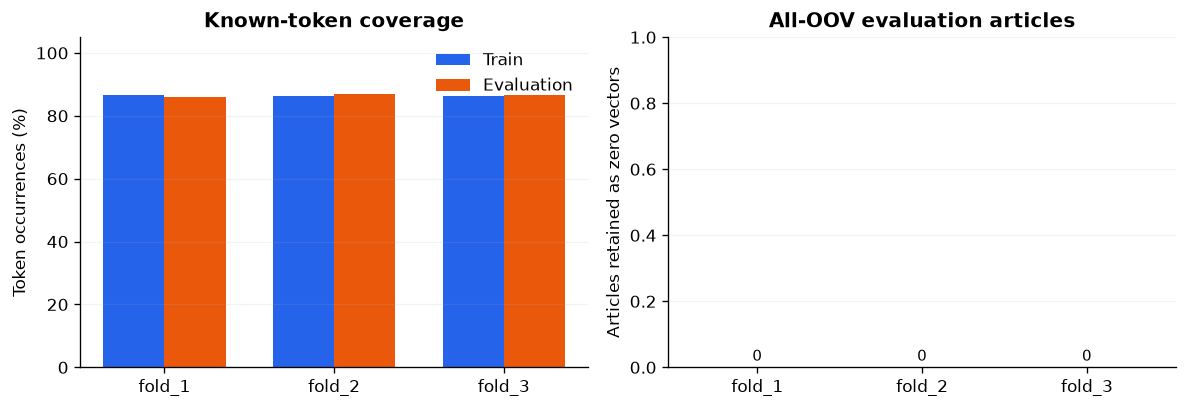

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = np.arange(len(text_coverage_summary))
axes[0].bar(x - .18, text_coverage_summary.train_token_coverage * 100, width=.36, color=COLORS[0], label="Train")
axes[0].bar(x + .18, text_coverage_summary.evaluation_token_coverage * 100, width=.36, color=COLORS[1], label="Evaluation")
axes[0].set_xticks(x, text_coverage_summary.run)
axes[0].set(title="Known-token coverage", ylabel="Token occurrences (%)", ylim=(0, 105))
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=.15)
values = text_coverage_summary.all_oov_articles.to_numpy(dtype=int)
axes[1].bar(x, values, color=[COLORS[i % 3] for i in x])
for index, value in enumerate(values):
    axes[1].annotate(str(value), (index, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
axes[1].set_xticks(x, text_coverage_summary.run)
axes[1].set(title="All-OOV evaluation articles", ylabel="Articles retained as zero vectors", ylim=(0, max(float(values.max()) * 1.3, 1)))
axes[1].grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Sampling uncertainty

95% intervals use 1,000 circular moving-block resamples of 10 evaluated observations. Reuse each fold's seed (`20261110 + run index`) and sampled dates across all training seeds. Average seed scores within each resample. These intervals condition on the fitted checkpoints; seed standard deviations are reported separately. Block settings and date order match L1-a/L1-b.

In [9]:
def block_intervals(frame, seed):
    reference = frame.loc[frame.training_seed.eq(SEEDS[0])].sort_values("Date")
    y = reference.y.to_numpy(dtype=int)
    probabilities = []
    for training_seed in SEEDS:
        rows = frame.loc[frame.training_seed.eq(training_seed)].sort_values("Date")
        assert rows.Date.tolist() == reference.Date.tolist() and rows.y.tolist() == reference.y.tolist()
        probabilities.append(rows.p_up.to_numpy(dtype=float))
    n, rng = len(y), np.random.default_rng(seed)
    length = min(BLOCK_LENGTH, n)
    sampled = {metric: [] for metric in METRICS}
    for _ in range(BOOTSTRAP_REPEATS):
        starts = rng.integers(0, n, size=int(np.ceil(n / length)))
        positions = ((starts[:, None] + np.arange(length)) % n).ravel()[:n]
        scores = [score_binary(y[positions], p[positions]) for p in probabilities]
        for metric in METRICS:
            values = [r[metric] for r in scores]
            sampled[metric].append(float(np.mean(values)))
    output = []
    for metric, values in sampled.items():
        valid = np.asarray(values, dtype=float)
        valid = valid[np.isfinite(valid)]
        low, high = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
        output.append({"metric": metric, "low_95": float(low), "high_95": float(high), "valid_resamples": len(valid)})
    return output

interval_rows = []
for run_index, run in enumerate(results.run, 1):
    for interval in block_intervals(predictions.loc[predictions.run.eq(run)], BOOTSTRAP_SEED + run_index):
        interval_rows.append({"run": run, **interval})
intervals = pd.DataFrame(interval_rows)
display(intervals.loc[intervals.metric.isin(["mcc", "macro_f1", "balanced_accuracy", "accuracy"])].round(4))

,run,metric,low_95,high_95,valid_resamples
0,fold_1,mcc,-0.0352,0.1627,1000
1,fold_1,macro_f1,0.4762,0.5747,1000
2,fold_1,balanced_accuracy,0.4825,0.5795,1000
3,fold_1,accuracy,0.4979,0.6013,1000
8,fold_2,mcc,0.0995,0.3145,1000
9,fold_2,macro_f1,0.5192,0.6444,1000
10,fold_2,balanced_accuracy,0.5448,0.6483,1000
11,fold_2,accuracy,0.5367,0.6667,1000
16,fold_3,mcc,-0.0548,0.1827,1000
17,fold_3,macro_f1,0.4373,0.5559,1000


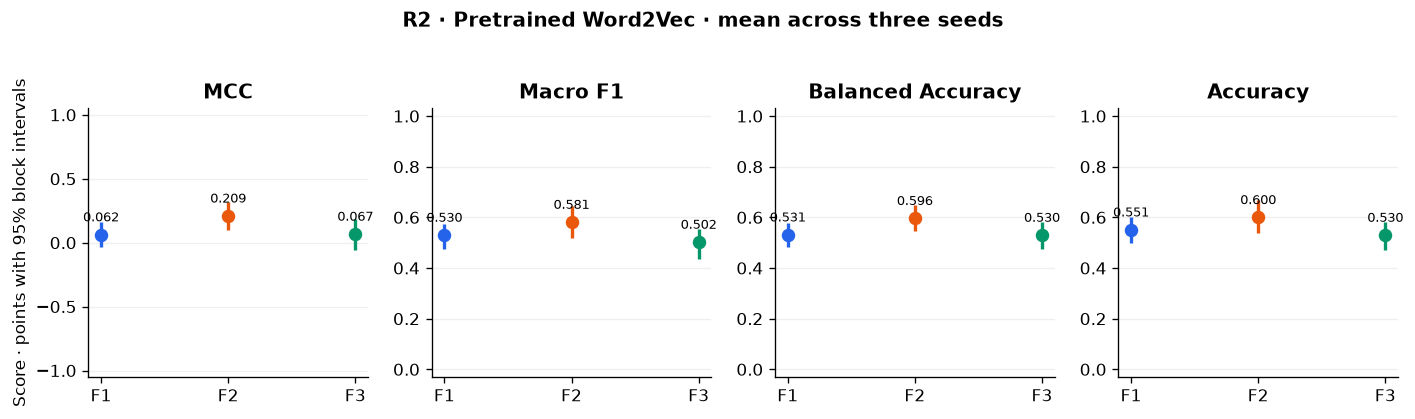

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, metric in zip(axes, ["mcc", "macro_f1", "balanced_accuracy", "accuracy"]):
    for index, row in results.reset_index(drop=True).iterrows():
        bounds = intervals.loc[intervals.run.eq(row["run"]) & intervals.metric.eq(metric)].iloc[0]
        value = row[metric]
        ax.vlines(index, bounds.low_95, bounds.high_95, color=COLORS[index % 3], linewidth=2)
        ax.scatter(index, value, color=COLORS[index % 3], s=50, zorder=3)
        ax.annotate(f"{value:.3f}", (index, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(results)), results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set_title(metric.replace("_", " ").upper() if metric == "mcc" else metric.replace("_", " ").title())
    ax.set_ylim(-1.05, 1.05) if metric == "mcc" else ax.set_ylim(-.03, 1.03)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Score · points with 95% block intervals")
fig.suptitle("R2 · Pretrained Word2Vec · mean across three seeds", y=1.04, fontweight="bold")
fig.tight_layout()
plt.show()

## Training curves

Solid = validation log loss; dashed = training log loss. Checkpoints are selected by MCC, then macro-F1, then log loss.


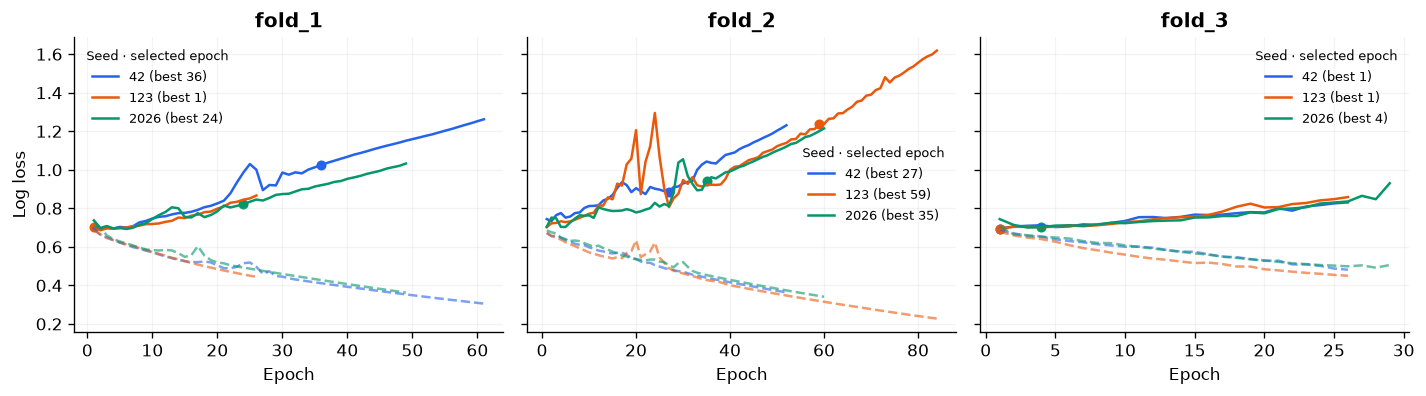

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, run in zip(axes, [f"fold_{i}" for i in sorted(folds.fold.unique())]):
    for index, seed in enumerate(SEEDS):
        curve = history.loc[history.run.eq(run) & history.seed.eq(seed)]
        best_epoch = int(fits.loc[fits.run.eq(run) & fits.seed.eq(seed), "best_epoch"].iloc[0])
        ax.plot(curve.epoch, curve.val_log_loss, color=COLORS[index], label=f"{seed} (best {best_epoch})")
        ax.plot(curve.epoch, curve.train_log_loss, "--", color=COLORS[index], alpha=.6)
        selected = curve.loc[curve.epoch.eq(best_epoch)].iloc[0]
        ax.scatter([best_epoch], [selected.val_log_loss], s=25, color=COLORS[index])
    ax.set(title=run, xlabel="Epoch")
    ax.grid(alpha=.15)
    ax.legend(title="Seed · selected epoch", fontsize=8, title_fontsize=8, frameon=False)
axes[0].set_ylabel("Log loss")
fig.tight_layout()
plt.show()

## Classes, confusion, and probability quality

Confusion annotations are mean counts across three seeds and row percentages. Each fold still has the same unique evaluation dates. Per-class metrics are seed means. Calibration pools seed predictions within bins, so its counts include repeated dates; it is not an ensemble or an independent-sample count.

,run,class,support,precision,recall,f1
0,fold_1,DOWN,64,0.4432,0.4271,0.4332
1,fold_1,UP,94,0.6200,0.6348,0.6263
2,fold_2,DOWN,78,0.6504,0.3974,0.4928
3,fold_2,UP,81,0.5780,0.7942,0.6690
4,fold_3,DOWN,79,0.5564,0.2954,0.3856
5,fold_3,UP,79,0.5201,0.7637,0.6187


,run,bin,prediction_entries,unique_dates,predicted_up,observed_up
0,fold_1,0,8,6,0.0407,0.7500
1,fold_1,1,5,5,0.1665,1.0000
2,fold_1,2,20,20,0.2690,0.6500
3,fold_1,3,38,34,0.3474,0.5263
4,fold_1,4,114,84,0.4547,0.5175
5,fold_1,5,125,86,0.5459,0.6640
6,fold_1,6,71,60,0.6453,0.5493
7,fold_1,7,35,30,0.7514,0.5714
8,fold_1,8,30,24,0.8494,0.7000
9,fold_1,9,28,15,0.9736,0.5714


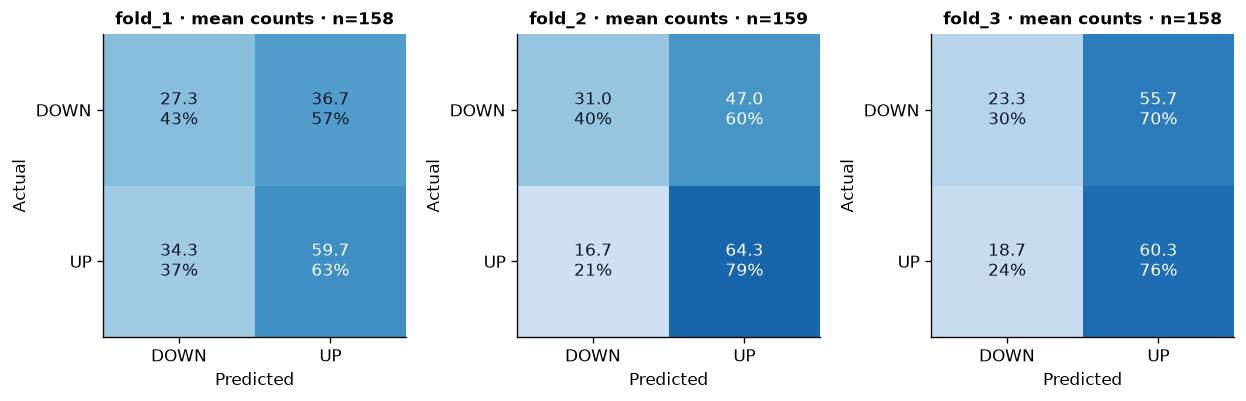

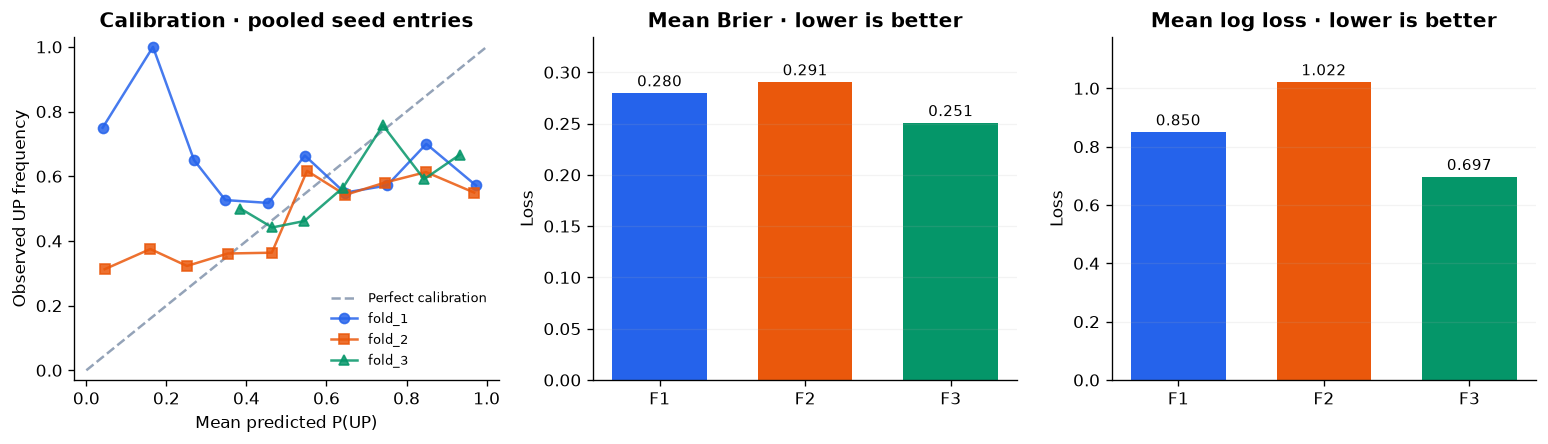

In [12]:
class_rows, calibration_rows = [], []
for row in results.to_dict("records"):
    for label, suffix in [("DOWN", "down"), ("UP", "up")]:
        class_rows.append({"run": row["run"], "class": label, "support": row[f"n_{suffix}"],
                           "precision": row[f"precision_{suffix}"], "recall": row[f"recall_{suffix}"], "f1": row[f"f1_{suffix}"]})
for run, frame in predictions.groupby("run", sort=False):
    bin_ids = np.minimum((frame.p_up.to_numpy() * 10).astype(int), 9)
    for bin_id in np.unique(bin_ids):
        group = frame.loc[bin_ids == bin_id]
        calibration_rows.append({"run": run, "bin": int(bin_id), "prediction_entries": len(group),
                                 "unique_dates": group.Date.nunique(), "predicted_up": float(group.p_up.mean()),
                                 "observed_up": float(group.y.mean())})
per_class, calibration = pd.DataFrame(class_rows), pd.DataFrame(calibration_rows)
display(per_class.round(4))
display(calibration.round(4))

fig, axes = plt.subplots(1, len(results), figsize=(3.5 * len(results), 3.3), squeeze=False)
for ax, row in zip(axes.ravel(), results.to_dict("records")):
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for actual in range(2):
        for predicted in range(2):
            ax.text(predicted, actual, f"{matrix[actual, predicted]:.1f}\n{normalized[actual, predicted]:.0%}",
                    ha="center", va="center", color="white" if normalized[actual, predicted] > .6 else "#0f172a")
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{row['run']} · mean counts · n={row['n']}", fontsize=10)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")
for index, (run, frame) in enumerate(calibration.groupby("run", sort=False)):
    frame = frame.sort_values("predicted_up")
    axes[0].plot(frame.predicted_up, frame.observed_up, marker=["o", "s", "^"][index % 3],
                 color=COLORS[index % 3], alpha=.85, label=run)
axes[0].set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean predicted P(UP)",
            ylabel="Observed UP frequency", title="Calibration · pooled seed entries")
axes[0].legend(fontsize=8, frameon=False)
x = np.arange(len(results))
for ax, metric, title in [(axes[1], "brier", "Mean Brier · lower is better"),
                           (axes[2], "log_loss", "Mean log loss · lower is better")]:
    ax.bar(x, results[metric], color=[COLORS[i % 3] for i in x], width=.65)
    ax.set_xticks(x, results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set(title=title, ylabel="Loss", ylim=(0, max(float(results[metric].max()) * 1.15, .01)))
    for i, value in enumerate(results[metric]):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Coverage and subgroup checks

Retain all eligible dates, including empty-news windows. Subgroup sizes count unique dates; scores average individual seeds. Weekday/gap groups use the target endpoint. Inspect small subsets cautiously.

,run,group,n,mcc,macro_f1,balanced_accuracy,accuracy
0,fold_1,all,158,0.0625,0.5297,0.5309,0.5506
1,fold_1,news_present,21,-0.0376,0.4304,0.4815,0.5238
2,fold_1,empty,137,0.0801,0.5389,0.5402,0.5547
3,fold_1,singleton,13,-0.0807,0.4148,0.4625,0.5385
4,fold_1,multi_article,8,0.0000,0.4392,0.5000,0.5000
5,fold_1,target_Monday,30,0.0869,0.5095,0.5332,0.5667
6,fold_1,target_other_weekday,128,0.0669,0.5287,0.5329,0.5469
7,fold_1,target_gap_1d,122,0.0637,0.5258,0.5312,0.5437
8,fold_1,target_gap_3d,28,0.1293,0.5282,0.5486,0.5833
9,fold_1,target_gap_other,8,0.1260,0.4990,0.5417,0.5417


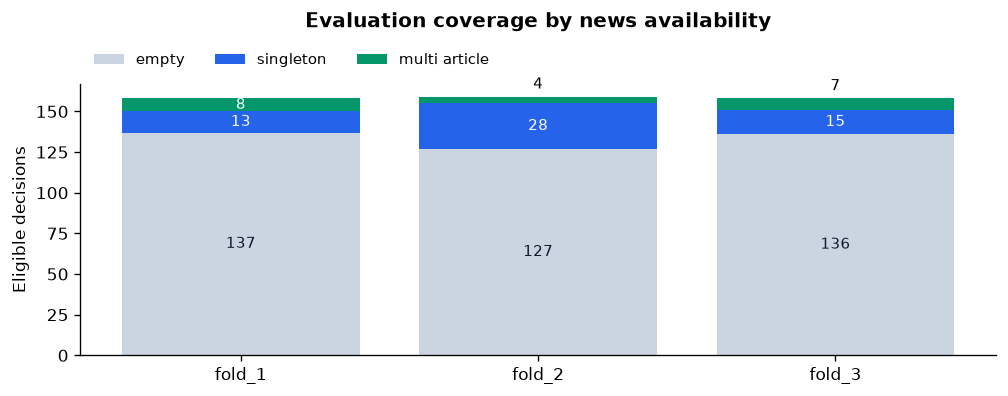

In [13]:
subgroup_rows = []
for run, all_seeds in predictions.groupby("run", sort=False):
    frame = all_seeds.loc[all_seeds.training_seed.eq(SEEDS[0])].sort_values("Date")
    masks = {"all": np.ones(len(frame), dtype=bool), "news_present": frame.n_berita.gt(0),
             "empty": frame.n_berita.eq(0), "singleton": frame.n_berita.eq(1),
             "multi_article": frame.n_berita.gt(1), "target_Monday": frame.target_weekday.eq(0),
             "target_other_weekday": frame.target_weekday.ne(0), "target_gap_1d": frame.realized_target_gap_days.eq(1),
             "target_gap_3d": frame.realized_target_gap_days.eq(3),
             "target_gap_other": ~frame.realized_target_gap_days.isin([1, 3])}
    for name, mask in masks.items():
        dates = frame.loc[mask, "Date"]
        selected = all_seeds.loc[all_seeds.Date.isin(dates)]
        if len(dates):
            scores = pd.DataFrame([score_binary(g.y, g.p_up) for _, g in selected.groupby("training_seed")]).mean().to_dict()
        else:
            scores = {m: np.nan for m in METRICS}
        subgroup_rows.append({"run": run, "group": name, **scores, "n": len(dates)})
subgroups = pd.DataFrame(subgroup_rows)
display(subgroups[["run", "group", "n", "mcc", "macro_f1", "balanced_accuracy", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
coverage = subgroups.loc[subgroups.group.isin(["empty", "singleton", "multi_article"])].pivot(index="run", columns="group", values="n")
coverage = coverage.reindex(results.run)
bottom = np.zeros(len(coverage))
for group, color in [("empty", "#cbd5e1"), ("singleton", COLORS[0]), ("multi_article", COLORS[2])]:
    values = coverage[group].to_numpy()
    ax.bar(coverage.index, values, bottom=bottom, color=color, label=group.replace("_", " "))
    for index, (base, value) in enumerate(zip(bottom, values)):
        if value >= 8:
            ax.text(index, base + value / 2, str(int(value)), ha="center", va="center", fontsize=9,
                    color="#0f172a" if group == "empty" else "white")
        elif value:
            ax.annotate(str(int(value)), (index, base + value), xytext=(0, 5),
                        textcoords="offset points", ha="center", fontsize=9)
    bottom += values
ax.set_ylabel("Eligible decisions")
ax.set_title("Evaluation coverage by news availability", pad=34)
ax.legend(frameon=False, ncol=3, bbox_to_anchor=(0, 1.01), loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## Result bundle

Metrics, intervals, predictions, classifier snapshots, source hashes, pretrained provenance, and token coverage are embedded below. Zero-only weights are omitted from inference snapshots. Cached pretrained subsets avoid full-table RAM use; Run All recreates article/window means. No run sidecars are written. Test scores never select the representation or filters.

In [14]:
files = [BASE / name for name in ["fold_manifest.csv", "final_fit_manifest.csv", "calendar_partitions.csv",
                                  "daily_market.csv", "pipeline_manifest.json", "feature_contract.json", "aligned_articles.jsonl", "news_windows.jsonl"]]
run_metadata = {
    "model_id": MODEL_ID, "condition": "pretrained_word2vec", "level": 2, "run_at_wib": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "final_test_evaluated": RUN_FINAL_TEST, "hard_prediction_rule": "P(UP) >= 0.5; threshold fixed",
    "probability_rule": "MLP logistic output; no calibration fitted",
    "input_predictors": FEATURES, "excluded_predictors": ["future outcomes", "sentiment labels", "legacy aligned dates", "collection tags"],
    "macro_inputs": [], "training_seeds": SEEDS, "threshold_tuned": False,
    "model": MLP_CONFIG, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "selection": ["validation MCC", "validation macro-F1", "negative validation log loss"],
    "scaler_fit": "Market: centered train; text: uncentered news-present train; availability: uncentered all train",
    "feature_blocks": {"market": MARKET_FEATURES, "text": TEXT_FEATURES, "availability": AVAIL_FEATURES},
    "shared_initialization": "Market rows and common hidden/output layers match L1-c; extra blocks use independent seeded Glorot",
    "text_pipeline": {"model": "word2vec-google-news-300", "native_dimension": WORD_DIM,
                      "common_text_width": TEXT_WIDTH, "token_view": "tokens_word2vec",
                      "case_sensitive": True, "lowercase_fallback": False,
                      "word_vector_normalization": "none", "word_pooling": "mean of in-vocabulary token occurrences",
                      "automatic_phrase_joining": False, "all_oov_article": "zero vector; retain count",
                      "training_on_project_text": False},
    "pretrained_model": pretrained_report,
    "level_3_eligible": True,
    "representation_contexts": [representation.provenance(run) for run, representation in text_models.items()],
    "fusion": "concatenation; no query/cross-attention/gate",
    "article_window_aggregation": "mean pretrained word vectors per article, then uniform article mean; empty/all-OOV inputs zero",
    "availability_transform": ["log1p(n_berita)", "has_news"], "final_epochs": "Per-seed median best epoch across development folds",
    "trainable_parameters_per_fit": sorted(fits.trainable_parameters.unique().tolist()),
    "prediction_effective_parameters_per_fit": sorted(fits.prediction_effective_parameters.unique().tolist()),
    "score_aggregation": "Mean individual-seed scores within fold, then equal-weight mean across validation folds; no ensemble",
    "bootstrap": {"method": "circular moving blocks", "repeats": BOOTSTRAP_REPEATS,
                  "block_length_evaluated_observations": BLOCK_LENGTH, "base_seed": BOOTSTRAP_SEED,
                  "run_seed_rule": "base_seed + 1-based run index in results", "confidence": .95,
                  "same_sampled_dates_across_training_seeds": True, "conditional_on_fixed_predictions": True},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__, "sklearn": sklearn.__version__},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in files},
    "source_sha256": pipeline["input_sha256"], "alignment_mode": pipeline["config"]["alignment_mode"],
    "geopolitical_policy": pipeline["config"]["geopolitical_policy"],
}
def to_records(frame):
    def clean(value):
        if isinstance(value, (pd.Timestamp, datetime)):
            return value.isoformat()
        if isinstance(value, np.generic):
            return clean(value.item())
        return None if pd.isna(value) else value
    return [{key: clean(value) for key, value in row.items()} for row in frame.to_dict("records")]
result_bundle = {"metadata": run_metadata, "fits": to_records(fits), "metrics": to_records(results),
                 "seed_metrics": to_records(seed_results), "seed_std": to_records(seed_std.reset_index()),
                 "validation_summary": to_records(validation_results.agg(["mean", "std"]).rename_axis("statistic").reset_index()),
                 "intervals": to_records(intervals), "per_class": to_records(per_class), "calibration": to_records(calibration),
                 "subgroups": to_records(subgroups), "predictions": to_records(predictions),
                 "history": to_records(history), "selected_models": snapshots, "text_coverage_summary": to_records(text_coverage_summary)}
json.dumps(result_bundle, allow_nan=False)
display({"application/json": result_bundle}, raw=True, metadata={"application/json": {"expanded": False}})
print(f"Stored {len(predictions)} seed-specific predictions across {predictions.Date.nunique()} dates; final test evaluated: {RUN_FINAL_TEST}.")

Stored 1425 seed-specific predictions across 475 dates; final test evaluated: False.
